# AST-HER: ordinary RocketPy versus native DATCOM

**Work in progress:** DATCOM currently produces poor flight predictions for several comparison rockets. The discrepancies are unresolved and are being investigated; these results should not be treated as validated predictions.

**AST-HER / Asteria has not flown. No measured altitude, velocity, CD or stability margin is available.** Percentages here are `100 × (DATCOM − RocketPy) / |RocketPy|`: model differences, not flight prediction errors.

Both use the saved current Asteria configuration, the same three liquid/pressurant tanks, thrust, mass/inertia, saved pressure/temperature/wind profile and launch conditions. Ordinary RocketPy uses Asteria's supplied `input/drag_curve.CSV`, copied with its hash recorded; this curve is not labelled as a measured wind-tunnel result. Native DATCOM derives its coefficients from the configured section geometry, with DAMP and powered nozzle-annulus/coast full-base drag. Its 20-point Mach and signed alpha grids and actual-atmosphere Reynolds schedules adapt from the ordinary flight, then twice from DATCOM flights. Scope is rail through apogee, without Asteria's hold-down clamp or PROTUB.

The configured ogive boattail is used by DATCOM. Ordinary RocketPy retains its conical-tail approximation because ogive tails are DATCOM-only; this geometric/model difference is explicit and contributes to the stability comparison. Nose, fin planform and mass/CG histories otherwise match. Unspecified construction is carbon fibre with vinyl; no numerical roughness is inferred from that label. Native AST-HER fin upper/lower thickness, bevel and leading-edge radius use the saved Asteria inputs.

The table compares apogee AGL, peak upward vertical velocity, loaded ignition Mach-zero static margin (DATCOM uses its lowest positive Mach), and zero-incidence powered/coast CD at Mach 0.6. Stability curves use each trajectory's actual Mach and CG. This comparison does not establish which model is more accurate.


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "rocketpy").is_dir())
DATA = ROOT / "docs/examples/datcom/comparison_data"
plt.rcParams.update({"axes.grid": True, "grid.alpha": .2})
def show(frame):
    display(frame.style.format(precision=3, na_rep="—"))
metrics = pd.read_csv(DATA / "asteria_metrics.csv")
show(metrics[["metric","unit","measured","rocketpy","datcom","datcom_vs_rocketpy_pct"]])
provenance = json.loads((DATA / "asteria_provenance.json").read_text())
assert provenance["flight_status"] == "AST-HER has not flown" and provenance["mass_cg_match"]


,metric,unit,measured,rocketpy,datcom,datcom_vs_rocketpy_pct
0,Apogee AGL,m,—,1030.111,1042.707,1.223
1,Peak upward vertical velocity,m/s,—,132.974,133.089,0.086
2,Initial static margin,cal,—,2.093,3.857,84.287
3,Powered CD at Mach 0.6,1,—,0.544,0.420,-22.774
4,Coast CD at Mach 0.6,1,—,0.544,0.447,-17.809


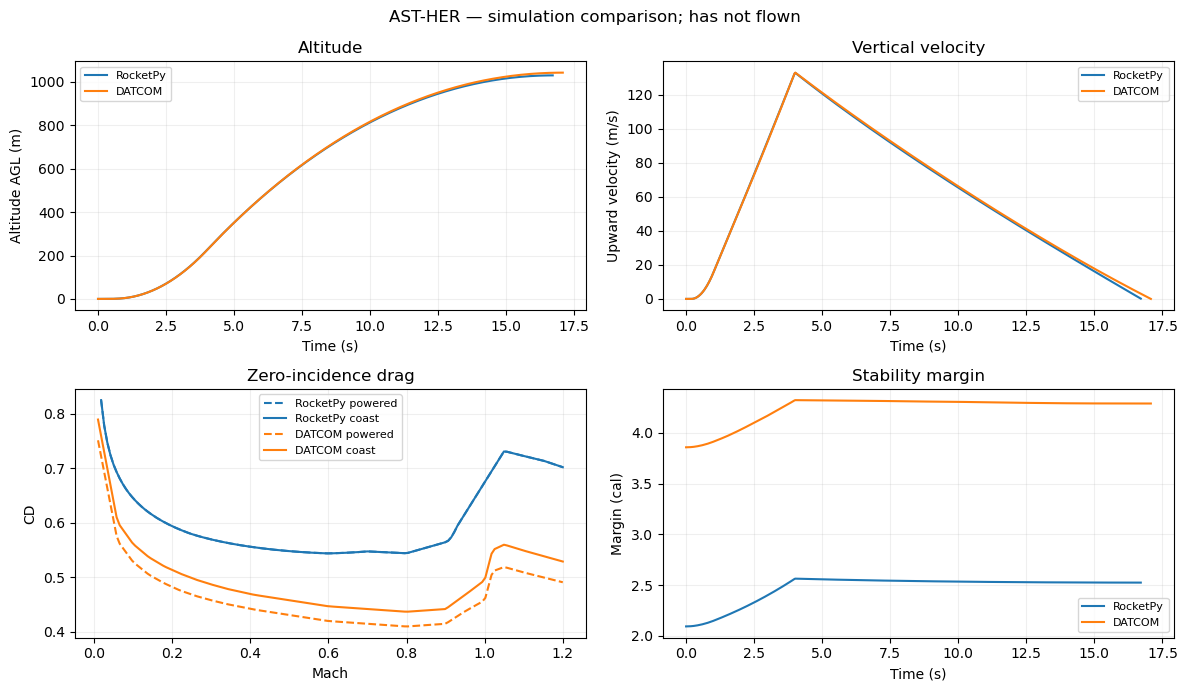

In [2]:
history = pd.read_csv(DATA / "asteria_histories.csv")
cd = pd.read_csv(DATA / "asteria_cd.csv")
fig, axes = plt.subplots(2,2,figsize=(12,7))
for prefix,label,color in [("rocketpy","RocketPy","tab:blue"),("datcom","DATCOM","tab:orange")]:
    for axis,column in [(axes[0,0],"altitude_agl_m"),(axes[0,1],"vz_m_s"),(axes[1,1],"margin_cal")]:
        axis.plot(history.time_s,history[f"{prefix}_{column}"],label=label,color=color)
    for phase,style in [("powered","--"),("coast","-")]:
        axes[1,0].plot(cd.mach,cd[f"{prefix}_{phase}_cd"],style,label=f"{label} {phase}",color=color)
for axis,title,xlabel,ylabel in [(axes[0,0],"Altitude","Time (s)","Altitude AGL (m)"),(axes[0,1],"Vertical velocity","Time (s)","Upward velocity (m/s)"),(axes[1,0],"Zero-incidence drag","Mach","CD"),(axes[1,1],"Stability margin","Time (s)","Margin (cal)")]:
    axis.set(title=title,xlabel=xlabel,ylabel=ylabel);axis.legend(fontsize=8)
fig.suptitle("AST-HER — simulation comparison; has not flown")
fig.tight_layout();plt.show()
